# Notebook 1 — Similarity Search by Hand

In Stage 2, a vector store found the chunks "closest" to a question. But what does "close"
mean for a list of 768 numbers? This notebook opens the box. You will compute the three
common similarity measures yourself, write a complete similarity search in a few lines, and
see why it gets slow when the data grows. That is the reason vector databases exist.

**What you will learn**

1. Three ways to measure how close two vectors are: L2 distance, dot product, and cosine
   similarity.
2. How to compute them by hand, then in one line of NumPy.
3. What normalized vectors are, and why they make the three measures agree.
4. The difference between a similarity and a distance.
5. A similarity search by hand: what every vector store does inside.
6. Why this simple search gets slow, and what the next notebooks do about it.

**Before you start**

```bash
ollama pull nomic-embed-text   # embedding model (~270 MB); no chat model needed here
uv sync
```

Then choose the `.venv` Python kernel for this notebook. ⏱️ About 35 minutes.

## 1. Setup

In [1]:
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from langchain_core.vectorstores import InMemoryVectorStore

from roadmap import get_embeddings

embeddings = get_embeddings()
print("Embedding model:", embeddings.model)

ASSETS = Path("assets")
ASSETS.mkdir(exist_ok=True)

Embedding model: nomic-embed-text


## 2. Three ways to measure "close"

![Three ways to measure "close"](assets/similarity_measures.svg)

An embedding is a **vector**: a list of numbers. With two numbers you can draw it as an
arrow on paper; an embedding model uses hundreds of numbers (its **dimension**), but the
math is the same. Three measures are common:

| Measure | Formula | Meaning |
|---|---|---|
| **L2 distance** (Euclidean distance) | $\sqrt{\sum_i (a_i - b_i)^2}$ | the length of the gap between the two arrow tips; 0 means identical, **smaller is closer** |
| **Dot product** | $\sum_i a_i b_i$ | how much the arrows point the same way, times their lengths; **bigger is closer** |
| **Cosine similarity** | $\dfrac{a \cdot b}{\lVert a \rVert \, \lVert b \rVert}$ | only the angle between the arrows: 1 = same direction, 0 = unrelated, −1 = opposite; **bigger is closer** |

$\lVert a \rVert$ is the **length** (also called the **norm**) of a vector:
$\sqrt{\sum_i a_i^2}$, the L2 distance from zero to its tip.

Let's write each formula as a plain Python function, using only loops and sums:

In [2]:
def l2_distance(a, b) -> float:
    return math.sqrt(sum((x - y) ** 2 for x, y in zip(a, b, strict=True)))


def dot_product(a, b) -> float:
    return sum(x * y for x, y in zip(a, b, strict=True))


def length(a) -> float:
    return math.sqrt(dot_product(a, a))


def cosine_similarity(a, b) -> float:
    return dot_product(a, b) / (length(a) * length(b))


q, a, b = [1, 1], [3, 3], [1, 0]  # the vectors from the diagram

for name, other in (("a", a), ("b", b)):
    print(
        f"q vs {name}:  L2 {l2_distance(q, other):.2f}   dot {dot_product(q, other):.2f}   "
        f"cosine {cosine_similarity(q, other):.2f}"
    )

q vs a:  L2 2.83   dot 6.00   cosine 1.00
q vs b:  L2 1.00   dot 1.00   cosine 0.71


The measures **disagree**. `a` points exactly the same way as `q` (cosine 1.00) but is three
times longer, so its tip is far away (L2 2.83). `b` is short like `q`, so its tip is close
(L2 1.00), but it points 45° away. The dot product even prefers `a` *because* it is long:
longer vectors get bigger dot products.

In practice you never write these loops. NumPy does the same math in fast, compiled code:

In [3]:
qv, av = np.array(q, dtype=float), np.array(a, dtype=float)

print("L2:    ", np.linalg.norm(qv - av))  # length of the difference
print("dot:   ", qv @ av)  # @ is the dot product (matrix multiplication)
print("cosine:", qv @ av / (np.linalg.norm(qv) * np.linalg.norm(av)))

L2:     2.8284271247461903
dot:    6.0
cosine: 1.0


## 3. Real embeddings: the two meanings of "bank"

Now the same math with real embeddings. All six sentences contain the word "bank", but in
two different meanings: three are about money, three are about rivers. A good embedding
model should place sentences with the same **meaning** close together, even though they
share the same word.

In [4]:
SENTENCES = [
    "I opened a savings account at the bank.",
    "The bank raised its interest rates this month.",
    "You need a bank card to pay at the counter.",
    "We had a picnic on the bank of the river.",
    "The river flooded its banks after the heavy rain.",
    "Ducks were resting on the grassy bank by the lake.",
]
LABELS = [
    "savings account",
    "interest rates",
    "bank card",
    "river picnic",
    "river flooded",
    "ducks by the lake",
]

vectors = np.array(embeddings.embed_documents(SENTENCES))
print("Shape:", vectors.shape, "-> 6 sentences, 768 numbers each")

Shape: (6, 768) -> 6 sentences, 768 numbers each


Let's compare every sentence with every other one. With NumPy, all pairs take one line per
measure. `vectors[:, None, :] - vectors[None, :, :]` subtracts every vector from every other
vector in one step (this is called **broadcasting**).

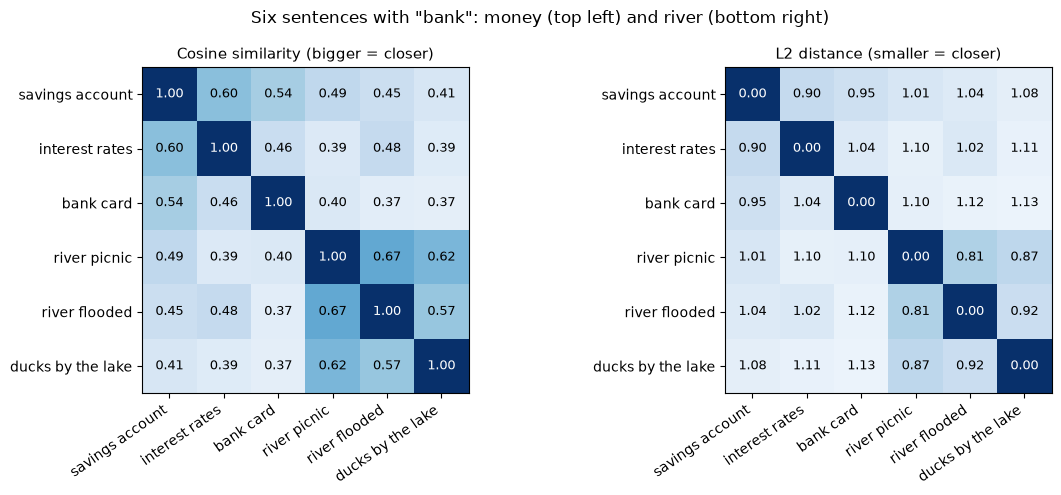

In [5]:
lengths = np.linalg.norm(vectors, axis=1)
cosine = (vectors @ vectors.T) / np.outer(lengths, lengths)
l2 = np.linalg.norm(vectors[:, None, :] - vectors[None, :, :], axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [
    (axes[0], cosine, "Cosine similarity (bigger = closer)", "Blues", 0.3, 1.0),
    (axes[1], l2, "L2 distance (smaller = closer)", "Blues_r", 0.0, 1.2),
]
for ax, matrix, title, cmap, vmin, vmax in panels:
    ax.imshow(matrix, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(LABELS)), LABELS, rotation=35, ha="right")
    ax.set_yticks(range(len(LABELS)), LABELS)
    for row in range(len(LABELS)):
        for col in range(len(LABELS)):
            value = matrix[row, col]
            dark = (value > 0.75) if cmap == "Blues" else (value < 0.45)
            ax.text(
                col,
                row,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if dark else "black",
            )
    ax.set_title(title, fontsize=11)
fig.suptitle('Six sentences with "bank": money (top left) and river (bottom right)')
fig.tight_layout()
fig.savefig(ASSETS / "bank_heatmaps.png", dpi=120)
plt.show()

**What to notice**

- Both heatmaps show two blocks: the money sentences (top left) and the river sentences
  (bottom right) are closer to each other than to the other group.
- The two heatmaps are mirror images: where the cosine similarity is high, the L2 distance
  is low. Section 4 explains why they always agree here.
- The diagonal is each sentence compared with itself: cosine 1.00, L2 0.00.
- The blocks are not perfect: single values overlap a little between the groups. Ranking is
  what counts, so let's check each sentence's closest neighbor:

In [6]:
for i, label in enumerate(LABELS):
    neighbor = next(j for j in np.argsort(-cosine[i]) if j != i)  # skip the sentence itself
    print(f"{label:<18} -> closest: {LABELS[neighbor]:<18} (cosine {cosine[i, neighbor]:.2f})")

savings account    -> closest: interest rates     (cosine 0.60)
interest rates     -> closest: savings account    (cosine 0.60)
bank card          -> closest: savings account    (cosine 0.54)
river picnic       -> closest: river flooded      (cosine 0.67)
river flooded      -> closest: river picnic       (cosine 0.67)
ducks by the lake  -> closest: river picnic       (cosine 0.62)


Every sentence finds a neighbor with the same meaning of "bank". The model understood the
context, not just the word.

## 4. Normalized vectors: when the three measures agree

Look at the lengths of these embeddings:

In [7]:
print("Lengths:", np.round(lengths, 4))
print("Dot product equals cosine:", np.allclose(vectors @ vectors.T, cosine))
print("L2² equals 2 - 2·cosine:  ", np.allclose(l2**2, 2 - 2 * cosine, atol=1e-5))

Lengths: [1. 1. 1. 1. 1. 1.]
Dot product equals cosine: True
L2² equals 2 - 2·cosine:   True


Every vector has length 1. Such vectors are called **normalized** (or **unit vectors**), and
`nomic-embed-text` in Ollama returns them this way. For normalized vectors:

- The **dot product equals the cosine similarity**, because the division by the lengths is
  a division by 1.
- The **L2 distance follows from the cosine**: $\text{L2}^2 = 2 - 2 \cdot \text{cosine}$. A
  higher cosine always means a smaller L2 distance.

So all three measures put the vectors in the **same order**. Every pair of our six
sentences lies on one curve:

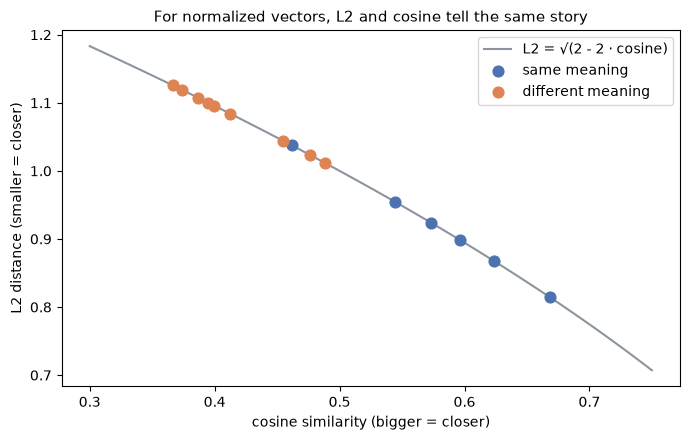

In [8]:
pairs = [(i, j) for i in range(len(SENTENCES)) for j in range(i + 1, len(SENTENCES))]
same_meaning = [(i < 3) == (j < 3) for i, j in pairs]

fig, ax = plt.subplots(figsize=(7, 4.5))
curve = np.linspace(0.3, 0.75, 100)
ax.plot(
    curve, np.sqrt(2 - 2 * curve), color="#8C959F", linewidth=1.5, label="L2 = √(2 - 2 · cosine)"
)
for same, color, label in (
    (True, "#4C72B0", "same meaning"),
    (False, "#DD8452", "different meaning"),
):
    xs = [cosine[i, j] for (i, j), s in zip(pairs, same_meaning, strict=True) if s == same]
    ys = [l2[i, j] for (i, j), s in zip(pairs, same_meaning, strict=True) if s == same]
    ax.scatter(xs, ys, color=color, s=60, label=label, zorder=3)
ax.set_xlabel("cosine similarity (bigger = closer)")
ax.set_ylabel("L2 distance (smaller = closer)")
ax.set_title("For normalized vectors, L2 and cosine tell the same story", fontsize=11)
ax.legend()
fig.tight_layout()
fig.savefig(ASSETS / "l2_vs_cosine.png", dpi=120)
plt.show()

Normalizing the vectors from section 2 shows the same effect: after scaling `q`, `a`, and
`b` to length 1, all three measures pick `a`.

In [9]:
def normalize(v) -> np.ndarray:
    v = np.asarray(v, dtype=float)
    return v / np.linalg.norm(v)


qn, an, bn = normalize(q), normalize(a), normalize(b)
for name, other in (("a", an), ("b", bn)):
    print(
        f"q vs {name}:  L2 {l2_distance(qn, other):.2f}   dot {dot_product(qn, other):.2f}   "
        f"cosine {cosine_similarity(qn, other):.2f}"
    )

q vs a:  L2 0.00   dot 1.00   cosine 1.00
q vs b:  L2 0.77   dot 0.71   cosine 0.71


### Similarity or distance?

A **similarity** is big when two vectors are close; a **distance** is small when they are
close. Vector databases usually report a distance, so they turn the cosine into a
**cosine distance**: $1 - \text{cosine}$.

| Measure | Kind | Closer means | Range for normalized vectors |
|---|---|---|---|
| L2 distance | distance | smaller | 0 to 2 |
| Dot product | similarity | bigger | −1 to 1 |
| Cosine similarity | similarity | bigger | −1 to 1 |
| Cosine distance (1 − cosine) | distance | smaller | 0 to 2 |

A "score" of 0.2 can mean "very close" (a cosine distance) or "far apart" (a cosine
similarity). Always check which one a library returns.

**Which measure should you use?**

- Check the length of your embeddings once. If it is 1, like here, all three measures rank
  the same, and the dot product is the cheapest to compute.
- If the lengths vary, use cosine similarity, or normalize the vectors first.
- Use the raw dot product on vectors of different lengths only when the length means
  something on purpose.

## 5. A similarity search by hand

A similarity search is now just three steps: embed the question, score it against every
stored vector, and keep the top k. Because all our vectors have length 1, the dot product
gives the cosine similarity directly.

In [10]:
def search(query: str, k: int = 3) -> None:
    query_vector = np.array(embeddings.embed_query(query))
    scores = vectors @ query_vector  # one cosine similarity per sentence
    best = np.argsort(-scores)[:k]  # indexes of the k highest scores
    print(f'"{query}"')
    for i in best:
        print(f"   {scores[i]:.3f}  {SENTENCES[i]}")
    print()


search("How can I borrow money to buy a house?")
search("Where is a good place to go fishing?")
search("bank")

"How can I borrow money to buy a house?"
   0.509  You need a bank card to pay at the counter.
   0.477  The bank raised its interest rates this month.
   0.469  I opened a savings account at the bank.

"Where is a good place to go fishing?"
   0.521  We had a picnic on the bank of the river.
   0.499  Ducks were resting on the grassy bank by the lake.
   0.470  The river flooded its banks after the heavy rain.

"bank"
   0.694  I opened a savings account at the bank.
   0.672  The bank raised its interest rates this month.
   0.619  You need a bank card to pay at the counter.



The first two questions do not contain the word "bank" at all, and still find the right
meaning. The last one is the bare word "bank", with no context. It lands on the money
sentences: in the text the model learned from, "bank" means money far more often than
river.

This is exactly what the vector store from Stage 2 does. `InMemoryVectorStore` returns the
same scores:

In [11]:
store = InMemoryVectorStore.from_texts(SENTENCES, embeddings)

for doc, score in store.similarity_search_with_score("Where is a good place to go fishing?", k=3):
    print(f"   {score:.3f}  {doc.page_content}")

   0.521  We had a picnic on the bank of the river.
   0.499  Ducks were resting on the grassy bank by the lake.
   0.470  The river flooded its banks after the heavy rain.


> **k-nearest neighbors (k-NN):** finding the k vectors closest to a query vector. Our
> `search()` is a **brute-force** (or **exact**) k-NN search: it compares the query with
> every vector, so it always finds the true top k.

## 6. Why brute-force search gets slow

First, a quick reminder why we use NumPy instead of our Python loops. Here are 2,000
random vectors with 768 numbers each:

In [12]:
rng = np.random.default_rng(0)
many = rng.standard_normal((2_000, 768), dtype=np.float32)
query_vector = rng.standard_normal(768, dtype=np.float32)

start = time.perf_counter()
loop_scores = [dot_product(row, query_vector.tolist()) for row in many.tolist()]
loop_ms = (time.perf_counter() - start) * 1000

start = time.perf_counter()
numpy_scores = many @ query_vector
numpy_ms = (time.perf_counter() - start) * 1000

print(f"Python loops: {loop_ms:8.2f} ms")
print(f"NumPy:        {numpy_ms:8.2f} ms  ({loop_ms / numpy_ms:,.0f} times faster)")
print("Same results:", np.allclose(loop_scores, numpy_scores, atol=1e-3))

Python loops:    97.12 ms
NumPy:            1.38 ms  (70 times faster)
Same results: True


NumPy is much faster, but it still compares the query with **every** vector. What happens
when a collection grows to many thousands of chunks? Random vectors are fine for this test:
the speed does not depend on the values.

 25,000 vectors:   2.37 ms per query,   77 MB of vectors


 50,000 vectors:   4.89 ms per query,  154 MB of vectors


100,000 vectors:   9.68 ms per query,  307 MB of vectors


150,000 vectors:  14.32 ms per query,  461 MB of vectors


200,000 vectors:  18.54 ms per query,  614 MB of vectors


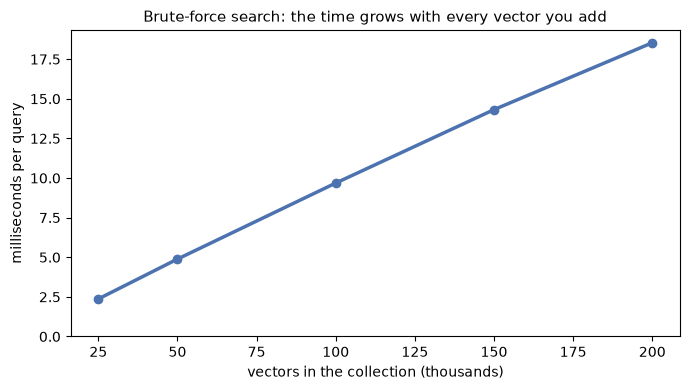

In [13]:
sizes = [25_000, 50_000, 100_000, 150_000, 200_000]
database = rng.standard_normal((sizes[-1], 768), dtype=np.float32)

times_ms = []
for n in sizes:
    part = database[:n]
    part @ query_vector  # warm-up run, not timed
    start = time.perf_counter()
    for _ in range(50):
        scores = part @ query_vector
        top5 = np.argpartition(-scores, 5)[:5]  # the 5 best, without sorting everything
    times_ms.append((time.perf_counter() - start) / 50 * 1000)
    print(
        f"{n:>7,} vectors: {times_ms[-1]:6.2f} ms per query, {part.nbytes / 1e6:4.0f} MB of vectors"
    )

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot([n / 1000 for n in sizes], times_ms, marker="o", color="#4C72B0", linewidth=2.5)
ax.set_xlabel("vectors in the collection (thousands)")
ax.set_ylabel("milliseconds per query")
ax.set_ylim(bottom=0)
ax.set_title("Brute-force search: the time grows with every vector you add", fontsize=11)
fig.tight_layout()
fig.savefig(ASSETS / "brute_force_time.png", dpi=120)
plt.show()

The line is straight: twice the vectors, twice the time. On this machine 200,000 vectors
already take about 19 ms per query and 614 MB of memory, and a real app may hold
millions of chunks and answer many users at the same time.

The next two notebooks fix this in two ways:

- **Notebook 2, ChromaDB:** a real vector database. It stores the vectors on disk, keeps
  metadata next to them, filters by it, and keeps the search fast as the data grows.
- **Notebook 3, FAISS:** indexes for **approximate nearest neighbor (ANN)** search. They look
  at only a small part of the vectors, so they are much faster, but they may sometimes
  miss one of the true top k. You will measure that trade-off.

## 7. Summary

| Idea | What it means | In code |
|---|---|---|
| L2 distance | Length of the gap between two vectors; smaller = closer | `np.linalg.norm(a - b)` |
| Dot product | Same direction times length; bigger = closer | `a @ b` |
| Cosine similarity | Only the angle; bigger = closer | `a @ b / (np.linalg.norm(a) * np.linalg.norm(b))` |
| Normalize | Scale a vector to length 1 | `v / np.linalg.norm(v)` |
| Normalized vectors | All three measures give the same order | `vectors @ query_vector` |
| Cosine distance | 1 − cosine; what many databases report | `1 - cosine` |
| Brute-force k-NN | Score every vector, keep the top k | `np.argsort(-(vectors @ q))[:k]` |

**Remember:** a vector store is "score every vector and sort". It is simple and exact, but
its cost grows with every vector you add.

➡️ **Next:** [Notebook 2 — ChromaDB](02_chromadb_basics.ipynb)